# Semiconductor Analysis

In [1]:
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spinmob

In [2]:
%matplotlib inline

sns.set_theme(
    "paper",
    "ticks",
    font="Helvetica"
)

In [22]:
data = spinmob.data.load("10-20.csv")

data["t5"] = data["t5"]#[288:1400] - data["t5"][271]
data["t6"] = data["t6"][1700:] - data["t5"][1700:]
data["v5"] = data["v5"][1700:]
data["v6"] = data["v6"][1700:]

data["t9"] = data["t9"][1700:]
data["T"] = data["T"][1700:]

0.0008179999999999854


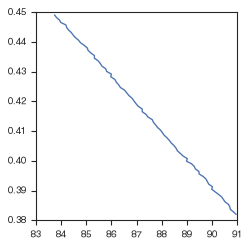

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(3.25, 3.25))
print(np.min(np.abs(np.diff(data["v5"]))))

plt.plot(data["T"], data["v6"])

In [24]:
l6 = 1e-2 * 535 / 1475
l6_uncertainty = 1e-3 * np.sqrt((0.5*10*115/1475)**2 + (0.5*10*146/1475)**2)

l5 = 1e-2 * 460 / 1475
l5_uncertainty = 1e-3 * np.sqrt((0.5*10*158/1475)**2 + (0.5*10*173/1475)**2)

h = 1e-2 * 453 / 1475
h_uncertainty = 1e-3 * 10 * 4 / 1475

d = 1e-2 * 133 / 1475
d_uncertainty = 1e-2 * 4 / 1475

A = d * h
A_uncertainty = A * np.sqrt((h_uncertainty/h)**2 + (d_uncertainty/d)**2)
print(A, "±", A_uncertainty)

2.7692731973570815e-06 ± 8.68018610315753e-08


In [27]:
model = lambda x, a, b: a*x + b

fit = sp.optimize.curve_fit(model, 1/data["T"], np.log(data["v6"]))
print(fit)

uncertainties = np.sqrt(np.diag(fit[1]))
ans = fit[0][0] * 2 * sp.constants.Boltzmann * 6241509343260179000
uncertainty = uncertainties[0] * 2 * sp.constants.Boltzmann * 6241509343260179000
print(ans, uncertainty)

(array([171.45667459,  -2.84267247]), array([[ 9.43927096e-01, -1.08072300e-02],
       [-1.08072300e-02,  1.23807312e-04]]))
0.029549987371422722 0.00016744497921632239


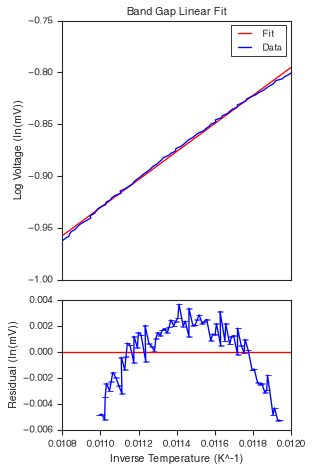

: 

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(4, 6), height_ratios=(2, 1))

space = np.linspace(1/data["T"][0], 1/data["T"][-1], 100)
vals = model(space, *fit[0])

ax[0].plot(space, vals, label="Fit", color="red")
ax[0].plot(1/data["T"], np.log(data["v6"]), label="Data", color="blue")
ax[0].legend()
ax[0].set_xticks([])
ax[0].set_ylabel("Log Voltage (ln(mV))")
ax[0].set_title("Band Gap Linear Fit")

residuals = np.log(data["v6"]) - model(1/data["T"], *fit[0])
ax[1].errorbar(1/data["T"], residuals, color="blue", yerr=0.00001/data["v5"])
ax[1].set_xlabel("Inverse Temperature (K^-1)")
ax[1].axhline(0, color="red")
ax[1].set_ylabel("Residual (ln(mV))")


fig.tight_layout()
fig.savefig("figure_2.png", dpi=600)